<a href="https://colab.research.google.com/github/FabioFavre/Simulacoes_Otimizacao/blob/main/Simulacao_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIMULAÇÃO 3 — Projeto de controlador LQR

**Base:** *Simulação 3.pdf*, páginas 1 e 2 — “Exemplo 01 / LQR Project”.  
**Ferramenta:** Python no Google Colab, com NumPy, SciPy e Matplotlib.

Determinar a matriz de ganho de realimentação ótima que minimiza o índice de desempenho LQR e apresentar a resposta ao degrau dos três estados do sistema, utilizando as matrizes `A`, `B`, `Q` e `R` fornecidas.


## 1. Definição das matrizes fornecidas

Modelo: $\dot{x}=Ax+Bu$, $y=Cx+Du$, com $x=[x_1,x_2,x_3]^T$.

$$A=\begin{bmatrix}0&1&0\\0&0&1\\0&-2&-3\end{bmatrix},\quad
B=\begin{bmatrix}0\\0\\1\end{bmatrix},\quad
Q=\operatorname{diag}(100,1,1),\quad R=[0{,}01].$$



In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are
from scipy.signal import StateSpace, step

np.set_printoptions(precision=8, suppress=True)

A = np.array([[0., 1., 0.],
              [0., 0., 1.],
              [0., -2., -3.]])
B = np.array([[0.], [0.], [1.]])
Q = np.diag([100., 1., 1.])
R = np.array([[0.01]])
C = np.array([[1., 0., 0.]])
D = np.array([[0.]])

print('SIMULAÇÃO 3 — ETAPA 1: MATRIZES DO SISTEMA')
for nome, matriz in [('A', A), ('B', B), ('Q', Q), ('R', R), ('C', C), ('D', D)]:
    print(f'\n{nome} =\n{matriz}')

SIMULAÇÃO 3 — ETAPA 1: MATRIZES DO SISTEMA

A =
[[ 0.  1.  0.]
 [ 0.  0.  1.]
 [ 0. -2. -3.]]

B =
[[0.]
 [0.]
 [1.]]

Q =
[[100.   0.   0.]
 [  0.   1.   0.]
 [  0.   0.   1.]]

R =
[[0.01]]

C =
[[1. 0. 0.]]

D =
[[0.]]


## 2. Cálculo do ganho ótimo LQR

**Enunciado da etapa:** determinar o ganho $K$ que minimiza o índice quadrático, conforme o comando MATLAB `K=lqr(A,B,Q,R)`.

$$J=\int_0^\infty (x^TQx+u^TRu)\,dt,\qquad u=-Kx.$$

A equação algébrica de Riccati é $A^TP+PA-PBR^{-1}B^TP+Q=0$ e $K=R^{-1}B^TP$.

In [10]:
print('SIMULAÇÃO 3 — ETAPA 2: GANHO LQR')
P = solve_continuous_are(A, B, Q, R)
K = np.linalg.solve(R, B.T @ P)
K1, K2, K3 = K.ravel()

residuo = A.T @ P + P @ A - P @ B @ np.linalg.solve(R, B.T @ P) + Q

print('Matriz P da equação de Riccati:\n', P)
print('\nGanho ótimo K =', K)
print(f'K1 = {K1:.8f}')
print(f'K2 = {K2:.8f}')
print(f'K3 = {K3:.8f}')
print(f'Resíduo máximo da equação de Riccati: {np.max(np.abs(residuo)):.3e}')

assert np.max(np.abs(residuo)) < 1e-7, 'A equação de Riccati não foi satisfeita.'

SIMULAÇÃO 3 — ETAPA 2: GANHO LQR
Matriz P da equação de Riccati:
 [[55.11997505 14.67105825  1.        ]
 [14.67105825  7.02668365  0.53119975]
 [ 1.          0.53119975  0.11671058]]

Ganho ótimo K = [[100.          53.11997505  11.67105825]]
K1 = 100.00000000
K2 = 53.11997505
K3 = 11.67105825
Resíduo máximo da equação de Riccati: 7.105e-13


## 3. Construção do sistema em malha fechada e entrada de referência

**Enunciado da etapa:** reproduzir as linhas do arquivo: `AA=A-B*K`, `BB=B*K1`, `CC=C`, `DD=D`.

Com referência unitária $r(t)$, a implementação usada no PDF é

$$\dot x=(A-BK)x+BK_1r(t),\quad y=Cx.$$

**Atenção:** `BB=B*K1` não é a matriz original de atuação `B`; é o canal de referência escolhido especificamente no exemplo. Ele faz o valor estacionário de $x_1$ ser 1 para degrau de referência unitário. Isto **não** significa que se deva adicionar uma segunda vez $-Kx$ durante a simulação.

In [11]:
print('SIMULAÇÃO 3 — ETAPA 3: SISTEMA EM MALHA FECHADA')
AA = A - B @ K
BB = B * K1
CC = C.copy()
DD = D.copy()

autovalores = np.linalg.eigvals(AA)
controlabilidade = np.hstack((B, A @ B, A @ A @ B))
print('AA = A - B@K =\n', AA)
print('\nBB = B*K1 =\n', BB)
print('\nAutovalores de AA =', autovalores)
print('Posto da controlabilidade:', np.linalg.matrix_rank(controlabilidade), '/ 3')
print('Estável?', np.all(np.real(autovalores) < 0))
assert np.all(np.real(autovalores) < 0), 'Sistema em malha fechada instável.'

SIMULAÇÃO 3 — ETAPA 3: SISTEMA EM MALHA FECHADA
AA = A - B@K =
 [[   0.            1.            0.        ]
 [   0.            0.            1.        ]
 [-100.          -55.11997505  -14.67105825]]

BB = B*K1 =
 [[  0.]
 [  0.]
 [100.]]

Autovalores de AA = [ -2.21407416+2.20470549j  -2.21407416-2.20470549j
 -10.24290993+0.j        ]
Posto da controlabilidade: 3 / 3
Estável? True


## 4. Resposta ao degrau e gráfico dos três estados

**Enunciado da etapa:** simular de 0 a 8 segundos, com passo de 0,01 s, e traçar $x_1$, $x_2$ e $x_3$ no mesmo gráfico, como na figura da página 2.

Adotam-se condições iniciais nulas e entrada $r(t)=1$ para $t\ge0$. A função `scipy.signal.step` calcula a resposta dos três estados usando a matriz de saída identidade para a visualização; o canal de saída $y=x_1$ é apresentado separadamente depois.

SIMULAÇÃO 3 — ETAPA 4: RESPOSTA AO DEGRAU


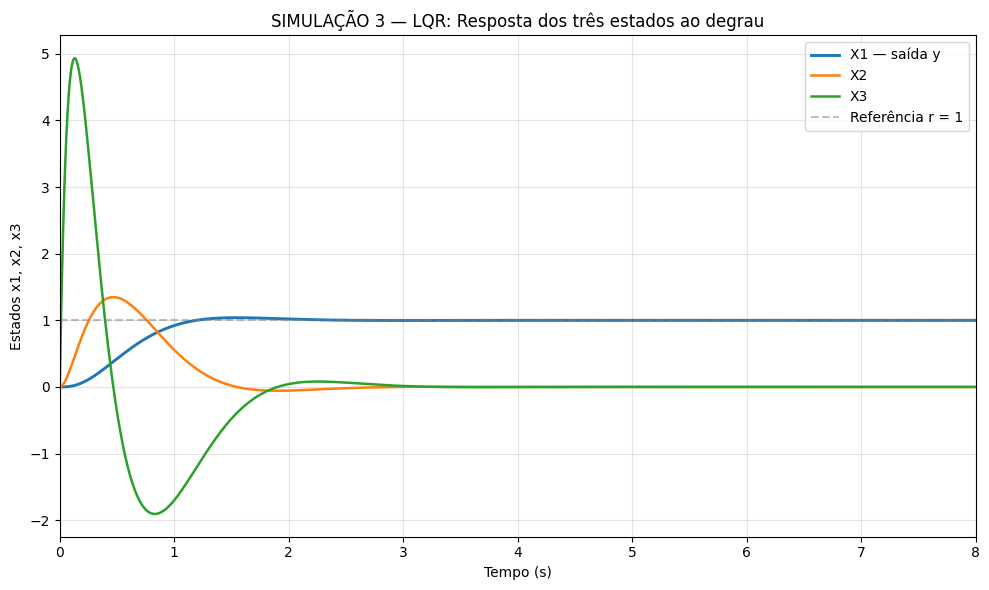

Estados no instante final t = 8 s:
x1(8) = 1.00000002
x2(8) = -0.00000011
x3(8) = 0.00000027


In [12]:
print('SIMULAÇÃO 3 — ETAPA 4: RESPOSTA AO DEGRAU')
t = np.arange(0., 8.001, 0.01)

# Para obter os três estados, usamos uma saída auxiliar de dimensão 3.
sistema_estados = StateSpace(AA, BB, np.eye(3), np.zeros((3, 1)))
t_out, estados = step(sistema_estados, T=t)
x1, x2, x3 = estados.T

plt.figure(figsize=(10, 6))
plt.plot(t_out, x1, label='X1 — saída y', linewidth=2.1)
plt.plot(t_out, x2, label='X2', linewidth=1.8)
plt.plot(t_out, x3, label='X3', linewidth=1.8)
plt.axhline(1, linestyle='--', color='gray', alpha=0.5, label='Referência r = 1')
plt.title('SIMULAÇÃO 3 — LQR: Resposta dos três estados ao degrau')
plt.xlabel('Tempo (s)')
plt.ylabel('Estados x1, x2, x3')
plt.xlim(0, 8)
plt.grid(True, alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

print('Estados no instante final t = 8 s:')
print(f'x1(8) = {x1[-1]:.8f}')
print(f'x2(8) = {x2[-1]:.8f}')
print(f'x3(8) = {x3[-1]:.8f}')

## 5. Saída $y=x_1$ e verificação do valor estacionário

**Análise complementar:** mostrar somente a saída $y(t)=x_1(t)$, o sinal que deve acompanhar a referência unitária. Calcular ainda o equilíbrio resolvendo $AA x_{ss}+BB=0$.

SIMULAÇÃO 3 — ETAPA 5: SAÍDA E EQUILÍBRIO


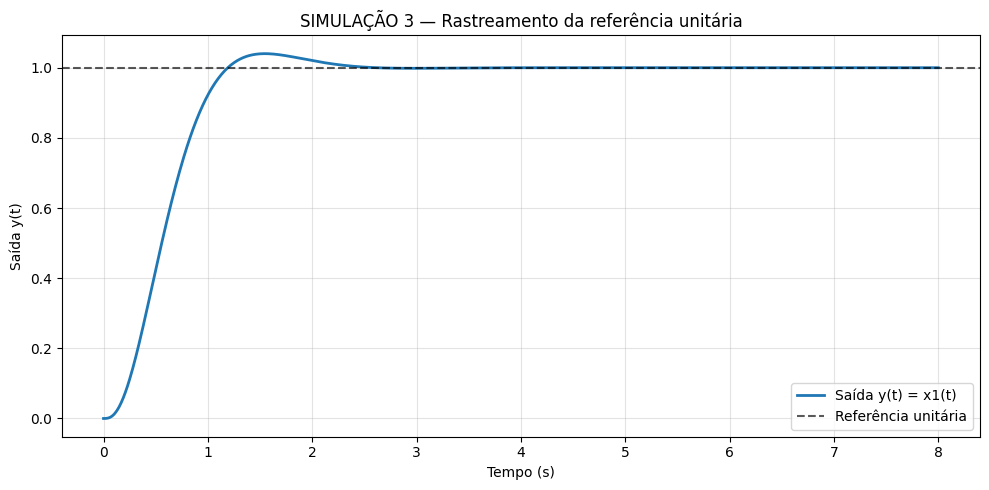

Estado estacionário calculado = [ 1. -0. -0.]
Saída estacionária y_ss = 1.00000000
Valor máximo de x1(t) = 1.04007767
Sobressinal da saída = 4.0078%
Erro estático para degrau unitário = 0.000e+00


In [13]:
print('SIMULAÇÃO 3 — ETAPA 5: SAÍDA E EQUILÍBRIO')
x_ss = np.linalg.solve(-AA, BB).ravel()
y_ss = (CC @ x_ss.reshape(-1, 1) + DD).item()

sistema_saida = StateSpace(AA, BB, CC, DD)
t_y, y = step(sistema_saida, T=t)

plt.figure(figsize=(10, 5))
plt.plot(t_y, y, linewidth=2, label='Saída y(t) = x1(t)')
plt.axhline(1, linestyle='--', color='black', alpha=0.65, label='Referência unitária')
plt.title('SIMULAÇÃO 3 — Rastreamento da referência unitária')
plt.xlabel('Tempo (s)')
plt.ylabel('Saída y(t)')
plt.grid(True, alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

print('Estado estacionário calculado =', x_ss)
print(f'Saída estacionária y_ss = {y_ss:.8f}')
print(f'Valor máximo de x1(t) = {np.max(x1):.8f}')
print(f'Sobressinal da saída = {max(0., (np.max(x1)-y_ss)/abs(y_ss)*100):.4f}%')
print(f'Erro estático para degrau unitário = {1-y_ss:.3e}')

assert np.allclose(x_ss, [1, 0, 0], atol=1e-8)
assert np.allclose(y, x1, atol=1e-8)

## 6. Sinal de controle e interpretação física

A lei completa aplicada ao modelo é $u(t)=-Kx(t)+K_1r(t)$. O gráfico abaixo ajuda a observar o esforço de controle.

SIMULAÇÃO 3 — ETAPA 6: SINAL DE CONTROLE


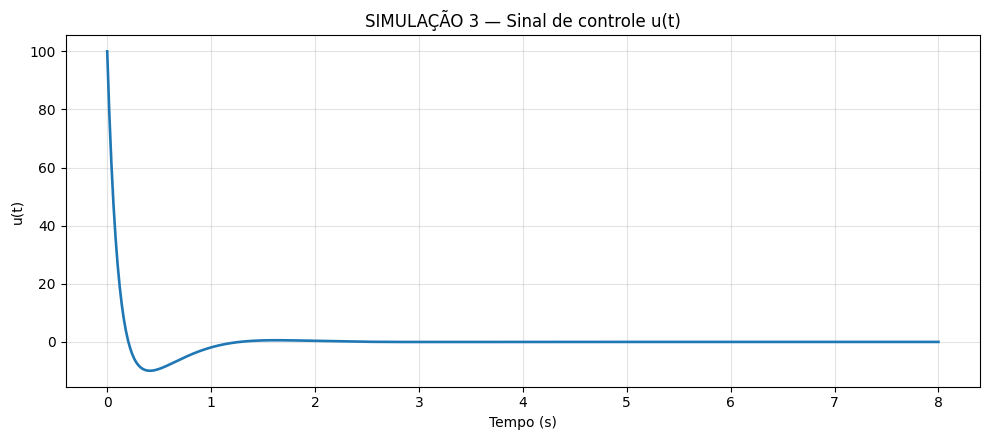

u(0+) = 100.00000
u(8 s) = 0.00000048


In [14]:
print('SIMULAÇÃO 3 — ETAPA 6: SINAL DE CONTROLE')
u = -estados @ K.T.ravel() + K1 * np.ones_like(t_out)
plt.figure(figsize=(10, 4.5))
plt.plot(t_out, u, linewidth=1.9)
plt.title('SIMULAÇÃO 3 — Sinal de controle u(t)')
plt.xlabel('Tempo (s)')
plt.ylabel('u(t)')
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()
print(f'u(0+) = {u[0]:.5f}')
print(f'u(8 s) = {u[-1]:.8f}')